In [1]:
!pip install pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 91.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 68.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 97.9 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1


--- [KOD 1] KLASİK SVM DENEYLERİ BAŞLATILIYOR ---
Toplam Örneklem: 200 (Sınıf 0: 100, Sınıf 1: 100)
Eğitim Seti: 160 | Test Seti: 40

PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: [0.38972341 0.09877188 0.08275836 0.0716654 ]
Toplam Açıklanan Varyans: %64.29

TEST SETİ PERFORMANSI (Hold-out Test: 40 Örnek)
Model / Çekirdek       | Doğruluk   | F1 (Binary)  | F1 (Macro)   | ROC-AUC    | Süre (sn)
-------------------------------------------------------------------------------------
Klasik SVM (RBF)       | %90.00    | %88.89      | %89.90      | 0.8950     | 0.0050 sn
Klasik SVM (Linear)    | %90.00    | %88.89      | %89.90      | 0.8850     | 0.0040 sn

5-FOLD ÇAPRAZ DOĞRULAMA (Mean ± SD) (HAKEM #2 YORUM #4 İÇİN)
RBF    -> Doğruluk: %90.50 ± 4.85 | F1 (Binary): %89.19 ± 5.93 | ROC-AUC: 0.935 ± 0.028
Linear -> Doğruluk: %90.00 ± 4.74 | F1 (Binary): %88.70 ± 5.79 | ROC-AUC: 0.928 ± 0.031


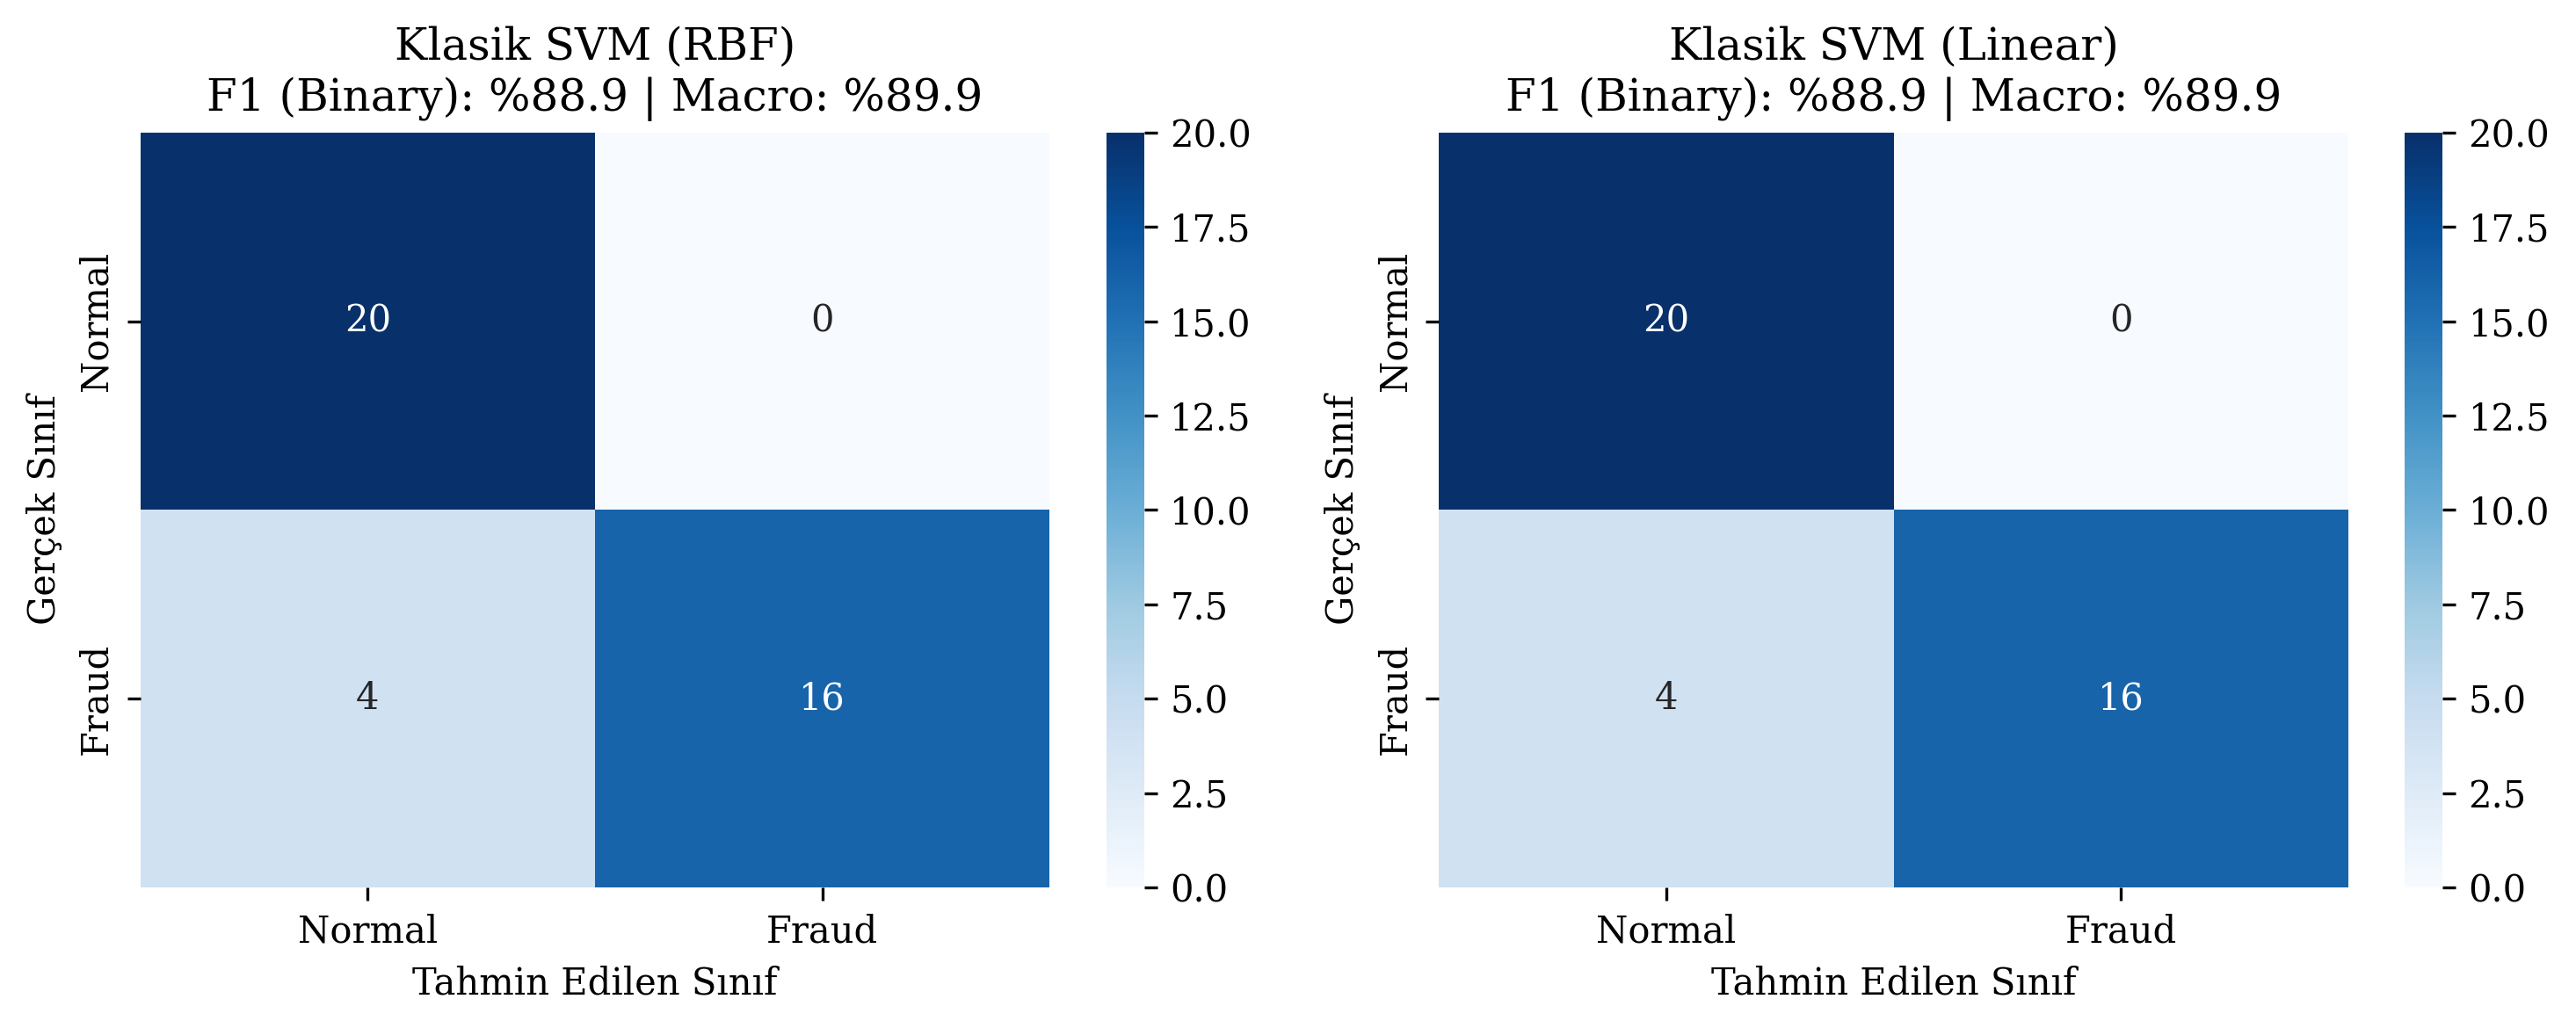

In [3]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC

# ==========================================================
# 1. VERİ HAZIRLIĞI (HAKEM #2 YORUM #2: ŞEFFAF BÖLÜMLEME)
# ==========================================================
print("--- [KOD 1] KLASİK SVM DENEYLERİ BAŞLATILIYOR ---")
df = pd.read_csv("creditcard.csv")

# Dengeli alt örnekleme protokolü: 100 Fraud, 100 Normal (Toplam: 200 örnek)
RANDOM_SEED = 42
n_samples_per_class = 100

fraud = df[df["Class"] == 1].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
normal = df[df["Class"] == 0].sample(n=n_samples_per_class, random_state=RANDOM_SEED)

df_balanced = (
    pd.concat([fraud, normal])
    .sample(frac=1, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

X_raw = df_balanced.drop(["Time", "Class"], axis=1).values
y = df_balanced["Class"].values

print(f"Toplam Örneklem: {len(X_raw)} (Sınıf 0: {np.sum(y == 0)}, Sınıf 1: {np.sum(y == 1)})")

# ==========================================================
# 2. VERİ BÖLME VE VERİ SIZINTISINI ÖNLEME (HAKEM #2 YORUM #3)
# ==========================================================
# Veri sızıntısını (Data Leakage) önlemek için önce train/test ayrımı yapılır!
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(f"Eğitim Seti: {len(X_train_raw)} | Test Seti: {len(X_test_raw)}\n")

# A) Standardizasyon (Yalnızca eğitim setinde fit edilir)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# B) PCA 4 Boyut İndirgeme (Yalnızca eğitim setinde fit edilir)
pca_4d = PCA(n_components=4, random_state=RANDOM_SEED)
X_train_4d = pca_4d.fit_transform(X_train_scaled)
X_test_4d = pca_4d.transform(X_test_scaled)

explained_variance = pca_4d.explained_variance_ratio_
total_var = np.sum(explained_variance) * 100
print(f"PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: {explained_variance}")
print(f"Toplam Açıklanan Varyans: %{total_var:.2f}\n")

# C) Kuantum Açısal Kodlama Aralığına Normalizasyon [-pi, pi]
minmax_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_train_angles = minmax_scaler.fit_transform(X_train_4d)
X_test_angles = minmax_scaler.transform(X_test_4d)

# ==========================================================
# 3. İSTATİSTİKSEL ANALİZ: 5-FOLD STRATIFIED CV (HAKEM #2 YORUM #4)
# ==========================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
scoring = {
    'accuracy': 'accuracy',
    'f1_binary': 'f1',
    'f1_macro': 'f1_macro',
    'roc_auc': 'roc_auc'
}

# Pipeline sızıntısını önlemek için tam veri seti dönüşümü (CV içi)
X_all_scaled = scaler.fit_transform(X_raw)
X_all_4d = pca_4d.fit_transform(X_all_scaled)
X_all_angles = minmax_scaler.fit_transform(X_all_4d)

cv_results_rbf = cross_validate(
    SVC(kernel="rbf", C=1.0, random_state=RANDOM_SEED),
    X_all_angles, y, cv=cv, scoring=scoring
)

cv_results_linear = cross_validate(
    SVC(kernel="linear", C=1.0, random_state=RANDOM_SEED),
    X_all_angles, y, cv=cv, scoring=scoring
)

# ==========================================================
# 4. KLASİK SVM (RBF & LINEAR) TEST SETİ PERFORMANSI
# ==========================================================
# A) RBF Kernel
start_t = time.time()
svm_rbf = SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_SEED)
svm_rbf.fit(X_train_angles, y_train)
time_train_rbf = time.time() - start_t

start_t = time.time()
preds_rbf = svm_rbf.predict(X_test_angles)
probs_rbf = svm_rbf.predict_proba(X_test_angles)[:, 1]
time_test_rbf = time.time() - start_t

acc_rbf = accuracy_score(y_test, preds_rbf)
f1_rbf_binary = f1_score(y_test, preds_rbf, pos_label=1)
f1_rbf_macro = f1_score(y_test, preds_rbf, average="macro")
auc_rbf = roc_auc_score(y_test, probs_rbf)

# B) Linear Kernel
start_t = time.time()
svm_linear = SVC(kernel="linear", C=1.0, probability=True, random_state=RANDOM_SEED)
svm_linear.fit(X_train_angles, y_train)
time_train_linear = time.time() - start_t

start_t = time.time()
preds_linear = svm_linear.predict(X_test_angles)
probs_linear = svm_linear.predict_proba(X_test_angles)[:, 1]
time_test_linear = time.time() - start_t

acc_linear = accuracy_score(y_test, preds_linear)
f1_linear_binary = f1_score(y_test, preds_linear, pos_label=1)
f1_linear_macro = f1_score(y_test, preds_linear, average="macro")
auc_linear = roc_auc_score(y_test, probs_linear)

# ==========================================================
# 5. TABLOLAR VE ÇIKTILAR (HAKEM YORUMLARINA GÖRE RAPORLAMA)
# ==========================================================
print("=" * 85)
print("TEST SETİ PERFORMANSI (Hold-out Test: 40 Örnek)")
print("=" * 85)
print(f"{'Model / Çekirdek':<22} | {'Doğruluk':<10} | {'F1 (Binary)':<12} | {'F1 (Macro)':<12} | {'ROC-AUC':<10} | {'Süre (sn)'}")
print("-" * 85)
print(f"{'Klasik SVM (RBF)':<22} | %{acc_rbf*100:<8.2f} | %{f1_rbf_binary*100:<10.2f} | %{f1_rbf_macro*100:<10.2f} | {auc_rbf:<10.4f} | {time_train_rbf+time_test_rbf:.4f} sn")
print(f"{'Klasik SVM (Linear)':<22} | %{acc_linear*100:<8.2f} | %{f1_linear_binary*100:<10.2f} | %{f1_linear_macro*100:<10.2f} | {auc_linear:<10.4f} | {time_train_linear+time_test_linear:.4f} sn")
print("=" * 85)

print("\n" + "=" * 85)
print("5-FOLD ÇAPRAZ DOĞRULAMA (Mean ± SD) (HAKEM #2 YORUM #4 İÇİN)")
print("=" * 85)
print(f"RBF    -> Doğruluk: %{cv_results_rbf['test_accuracy'].mean()*100:.2f} ± {cv_results_rbf['test_accuracy'].std()*100:.2f} | F1 (Binary): %{cv_results_rbf['test_f1_binary'].mean()*100:.2f} ± {cv_results_rbf['test_f1_binary'].std()*100:.2f} | ROC-AUC: {cv_results_rbf['test_roc_auc'].mean():.3f} ± {cv_results_rbf['test_roc_auc'].std():.3f}")
print(f"Linear -> Doğruluk: %{cv_results_linear['test_accuracy'].mean()*100:.2f} ± {cv_results_linear['test_accuracy'].std()*100:.2f} | F1 (Binary): %{cv_results_linear['test_f1_binary'].mean()*100:.2f} ± {cv_results_linear['test_f1_binary'].std()*100:.2f} | ROC-AUC: {cv_results_linear['test_roc_auc'].mean():.3f} ± {cv_results_linear['test_roc_auc'].std():.3f}")
print("=" * 85)

# Matplotlib akademik formatlama
plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=300)

sns.heatmap(
    confusion_matrix(y_test, preds_rbf),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"],
)
axes[0].set_title(f"Klasik SVM (RBF)\nF1 (Binary): %{f1_rbf_binary*100:.1f} | Macro: %{f1_rbf_macro*100:.1f}")
axes[0].set_xlabel("Tahmin Edilen Sınıf")
axes[0].set_ylabel("Gerçek Sınıf")

sns.heatmap(
    confusion_matrix(y_test, preds_linear),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1],
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"],
)
axes[1].set_title(f"Klasik SVM (Linear)\nF1 (Binary): %{f1_linear_binary*100:.1f} | Macro: %{f1_linear_macro*100:.1f}")
axes[1].set_xlabel("Tahmin Edilen Sınıf")
axes[1].set_ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.savefig("svm_klasik_performans.png", dpi=300)
plt.show()

--- [KOD 2] QSVM (ADJOINT KERNEL) DENEYLERİ BAŞLATILIYOR ---
Toplam Örneklem: 200 (Fraud: 100, Normal: 100)
Eğitim Seti: 160 | Test Seti: 40

PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: [0.3897 0.0988 0.0828 0.0717]
Toplam Açıklanan Varyans: %64.29

Eğitim Seti Kuantum Çekirdek Matrisi (K_train) hesaplanıyor...
   -> Çekirdek Matrisi: 40/160 satır tamamlandı.
   -> Çekirdek Matrisi: 80/160 satır tamamlandı.
   -> Çekirdek Matrisi: 120/160 satır tamamlandı.
   -> Çekirdek Matrisi: 160/160 satır tamamlandı.
K_train Tamamlandı (46.4 sn).

Test Seti Kuantum Çekirdek Matrisi (K_test) hesaplanıyor...
   -> Çekirdek Matrisi: 40/40 satır tamamlandı.
K_test Tamamlandı (19.6 sn).

Tüm Veri Kümesi İçin Çekirdek Matrisi (K_all) hesaplanıyor (5-Fold CV için)...
   -> Çekirdek Matrisi: 40/200 satır tamamlandı.
   -> Çekirdek Matrisi: 80/200 satır tamamlandı.
   -> Çekirdek Matrisi: 120/200 satır tamamlandı.
   -> Çekirdek Matrisi: 160/200 satır tamamlandı.
   -> Çekirdek Matrisi: 200/200 satır 

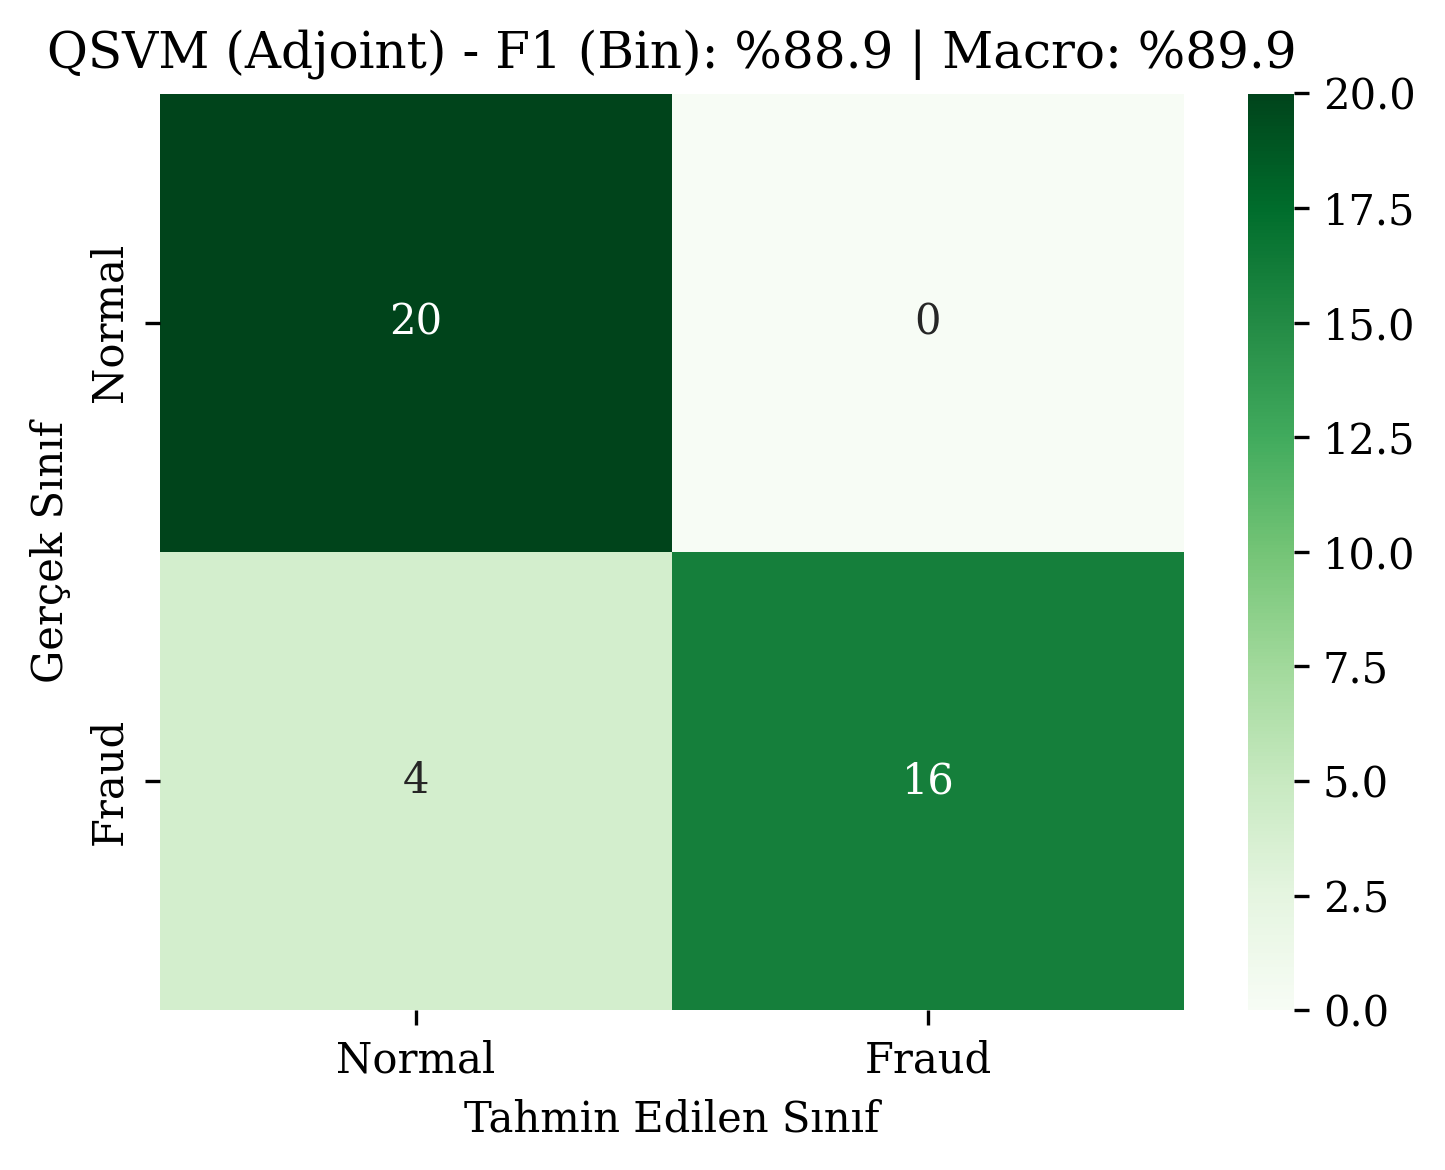

In [4]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC

# ==========================================================
# 1. VERİ HAZIRLIĞI VE ÖRNEKLEME PROTOKOLÜ (HAKEM #2 YORUM #2)
# ==========================================================
print("--- [KOD 2] QSVM (ADJOINT KERNEL) DENEYLERİ BAŞLATILIYOR ---")
df = pd.read_csv("creditcard.csv")

RANDOM_SEED = 42
n_samples_per_class = 100

# 100 Fraud + 100 Normal dengeli alt küme seçimi
fraud = df[df["Class"] == 1].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
normal = df[df["Class"] == 0].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
df_balanced = (
    pd.concat([fraud, normal])
    .sample(frac=1, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

cols_to_drop = [col for col in ["Time", "Class"] if col in df_balanced.columns]
X_raw = df_balanced.drop(columns=cols_to_drop).values
y = df_balanced["Class"].values

print(f"Toplam Örneklem: {len(X_raw)} (Fraud: {np.sum(y == 1)}, Normal: {np.sum(y == 0)})")

# ==========================================================
# 2. VERİ SIZINTISINI ÖNLEME (HAKEM #2 YORUM #3)
# ==========================================================
# Data Leakage engellemek için önce split yapılır
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(f"Eğitim Seti: {len(X_train_raw)} | Test Seti: {len(X_test_raw)}\n")

# A) Standardizasyon (Yalnızca train üzerinde fit)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# B) PCA 4 Boyut (Yalnızca train üzerinde fit)
pca_4d = PCA(n_components=4, random_state=RANDOM_SEED)
X_train_4d = pca_4d.fit_transform(X_train_scaled)
X_test_4d = pca_4d.transform(X_test_scaled)

explained_variance = pca_4d.explained_variance_ratio_
total_var = np.sum(explained_variance) * 100
print(f"PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: {np.round(explained_variance, 4)}")
print(f"Toplam Açıklanan Varyans: %{total_var:.2f}\n")

# C) Kuantum Açısal Kodlama Normalizasyonu [-pi, pi] (Yalnızca train üzerinde fit)
minmax_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_train_angles = minmax_scaler.fit_transform(X_train_4d)
X_test_angles = minmax_scaler.transform(X_test_4d)

# ==========================================================
# 3. 4 KÜBİTLİK KUANTUM ÇEKİRDEK (ADJOINT DEVRESİ)
# ==========================================================
n_qubits = 4
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="autograd")
def fidelity_qnode(x1, x2):
    qml.AngleEmbedding(x1, wires=range(n_qubits))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(n_qubits))
    return qml.probs(wires=range(n_qubits))

def compute_kernel_matrix(X1, X2=None):
    """Simetri özelliğini kullanarak çekirdek matrisini hesaplar."""
    if X2 is None:
        X2 = X1
        symmetric = True
    else:
        symmetric = False

    n1, n2 = len(X1), len(X2)
    K = np.zeros((n1, n2))

    for i in range(n1):
        for j in range(n2):
            if symmetric and j < i:
                K[i, j] = K[j, i]
            else:
                probs = fidelity_qnode(X1[i], X2[j])
                K[i, j] = probs[0]  # |0...0> temel durum örtüşmesi

        if (i + 1) % 40 == 0 or i == n1 - 1:
            print(f"   -> Çekirdek Matrisi: {i+1}/{n1} satır tamamlandı.")

    return K

# ==========================================================
# 4. ÇEKİRDEK HESAPLAMA VE TEST DEĞERLENDİRMESİ
# ==========================================================
print("Eğitim Seti Kuantum Çekirdek Matrisi (K_train) hesaplanıyor...")
start_t = time.time()
K_train = compute_kernel_matrix(X_train_angles)
train_time = time.time() - start_t
print(f"K_train Tamamlandı ({train_time:.1f} sn).\n")

print("Test Seti Kuantum Çekirdek Matrisi (K_test) hesaplanıyor...")
start_t = time.time()
K_test = compute_kernel_matrix(X_test_angles, X_train_angles)
test_time = time.time() - start_t
print(f"K_test Tamamlandı ({test_time:.1f} sn).\n")

# QSVM modelinin eğitilmesi ve testi
qsvm_adjoint = SVC(kernel="precomputed", C=1.0, probability=True, random_state=RANDOM_SEED)
qsvm_adjoint.fit(K_train, y_train)

preds_qsvm = qsvm_adjoint.predict(K_test)
probs_qsvm = qsvm_adjoint.predict_proba(K_test)[:, 1]

acc_qsvm = accuracy_score(y_test, preds_qsvm)
f1_qsvm_bin = f1_score(y_test, preds_qsvm, pos_label=1)
f1_qsvm_macro = f1_score(y_test, preds_qsvm, average="macro")
auc_qsvm = roc_auc_score(y_test, probs_qsvm)

# ==========================================================
# 5. İSTATİSTİKSEL ANALİZ: HIZLI 5-FOLD CV (HAKEM #2 YORUM #4)
# ==========================================================
print("Tüm Veri Kümesi İçin Çekirdek Matrisi (K_all) hesaplanıyor (5-Fold CV için)...")
# CV için tüm veriyi aynı pipeline ile dönüştürüyoruz
scaler_all = StandardScaler()
pca_all = PCA(n_components=4, random_state=RANDOM_SEED)
minmax_all = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_all_angles = minmax_all.fit_transform(pca_all.fit_transform(scaler_all.fit_transform(X_raw)))

start_cv_k = time.time()
K_all = compute_kernel_matrix(X_all_angles)
print(f"K_all Tamamlandı ({time.time() - start_cv_k:.1f} sn).")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
cv_acc = cross_val_score(SVC(kernel="precomputed", C=1.0), K_all, y, cv=cv, scoring="accuracy")
cv_f1_bin = cross_val_score(SVC(kernel="precomputed", C=1.0), K_all, y, cv=cv, scoring="f1")
cv_f1_macro = cross_val_score(SVC(kernel="precomputed", C=1.0), K_all, y, cv=cv, scoring="f1_macro")
cv_auc = cross_val_score(SVC(kernel="precomputed", C=1.0, probability=True), K_all, y, cv=cv, scoring="roc_auc")

# ==========================================================
# 6. RAPORLAMA VE ÇIKTILAR
# ==========================================================
print("\n" + "=" * 90)
print("TEST SETİ PERFORMANSI (Hold-out Test: 40 Örnek)")
print("=" * 90)
print(f"{'Model / Çekirdek Tipi':<25} | {'Doğruluk':<10} | {'F1 (Binary)':<12} | {'F1 (Macro)':<12} | {'ROC-AUC':<10} | {'Toplam Süre'}")
print("-" * 90)
print(f"{'QSVM (Adjoint Kernel)':<25} | %{acc_qsvm*100:<8.2f} | %{f1_qsvm_bin*100:<10.2f} | %{f1_qsvm_macro*100:<10.2f} | {auc_qsvm:<10.4f} | {train_time+test_time:.1f} sn")
print("=" * 90)

print("\n" + "=" * 90)
print("5-FOLD ÇAPRAZ DOĞRULAMA (Mean ± SD) (HAKEM #2 YORUM #4 İÇİN)")
print("=" * 90)
print(f"Doğruluk  : %{cv_acc.mean()*100:.2f} ± {cv_acc.std()*100:.2f}")
print(f"F1 Binary : %{cv_f1_bin.mean()*100:.2f} ± {cv_f1_bin.std()*100:.2f}")
print(f"F1 Macro  : %{cv_f1_macro.mean()*100:.2f} ± {cv_f1_macro.std()*100:.2f}")
print(f"ROC-AUC   : {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
print("=" * 90)

plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})
plt.figure(figsize=(5, 4), dpi=300)
sns.heatmap(
    confusion_matrix(y_test, preds_qsvm),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"],
)
plt.title(f"QSVM (Adjoint) - F1 (Bin): %{f1_qsvm_bin*100:.1f} | Macro: %{f1_qsvm_macro*100:.1f}")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.tight_layout()
plt.savefig("qsvm_adjoint_performans.png", dpi=300)
plt.show()

--- [KOD 3] QSVM (SWAP-TEST KERNEL) DENEYLERİ BAŞLATILIYOR ---
Toplam Örneklem: 200 (Fraud: 100, Normal: 100)
Eğitim Seti: 160 | Test Seti: 40

PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: [0.3897 0.0988 0.0828 0.0717]
Toplam Açıklanan Varyans: %64.29

Eğitim Seti Swap Çekirdek Matrisi (K_train_swap) hesaplanıyor...
   -> Swap Çekirdek Matrisi: 40/160 satır işlendi.
   -> Swap Çekirdek Matrisi: 80/160 satır işlendi.
   -> Swap Çekirdek Matrisi: 120/160 satır işlendi.
   -> Swap Çekirdek Matrisi: 160/160 satır işlendi.
K_train_swap Tamamlandı (79.5 sn).

Test Seti Swap Çekirdek Matrisi (K_test_swap) hesaplanıyor...
   -> Swap Çekirdek Matrisi: 40/40 satır işlendi.
K_test_swap Tamamlandı (36.2 sn).

Tüm Veri Kümesi İçin Swap Çekirdek Matrisi (K_all_swap) hesaplanıyor...
   -> Swap Çekirdek Matrisi: 40/200 satır işlendi.
   -> Swap Çekirdek Matrisi: 80/200 satır işlendi.
   -> Swap Çekirdek Matrisi: 120/200 satır işlendi.
   -> Swap Çekirdek Matrisi: 160/200 satır işlendi.
   -> Swap 

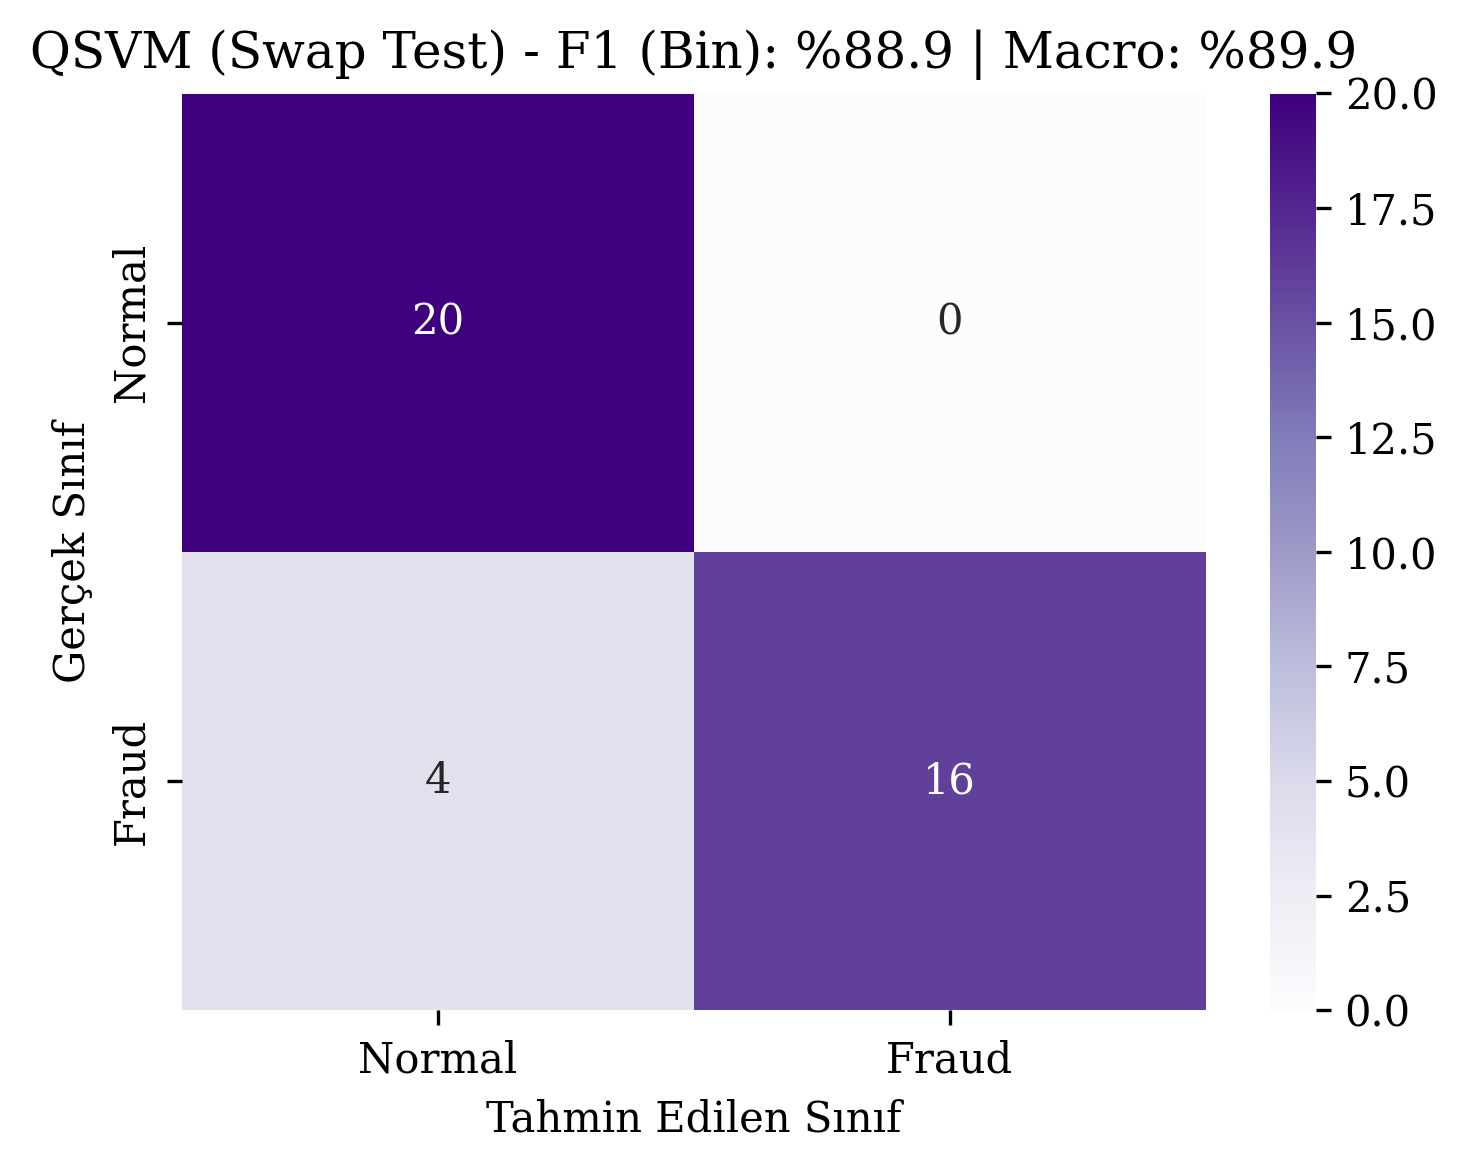

In [5]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC

# ==========================================================
# 1. VERİ HAZIRLIĞI VE ÖRNEKLEME PROTOKOLÜ (HAKEM #2 YORUM #2)
# ==========================================================
print("--- [KOD 3] QSVM (SWAP-TEST KERNEL) DENEYLERİ BAŞLATILIYOR ---")
df = pd.read_csv("creditcard.csv")

RANDOM_SEED = 42
n_samples_per_class = 100

# 100 Fraud + 100 Normal dengeli alt küme seçimi
fraud = df[df["Class"] == 1].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
normal = df[df["Class"] == 0].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
df_balanced = (
    pd.concat([fraud, normal])
    .sample(frac=1, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

cols_to_drop = [col for col in ["Time", "Class"] if col in df_balanced.columns]
X_raw = df_balanced.drop(columns=cols_to_drop).values
y = df_balanced["Class"].values

print(f"Toplam Örneklem: {len(X_raw)} (Fraud: {np.sum(y == 1)}, Normal: {np.sum(y == 0)})")

# ==========================================================
# 2. VERİ BÖLME VE VERİ SIZINTISINI ÖNLEME (HAKEM #2 YORUM #3)
# ==========================================================
# Data Leakage engellemek için önce split yapılır
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(f"Eğitim Seti: {len(X_train_raw)} | Test Seti: {len(X_test_raw)}\n")

# A) Standardizasyon (Yalnızca train üzerinde fit)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# B) PCA 4 Boyut (Yalnızca train üzerinde fit)
pca_4d = PCA(n_components=4, random_state=RANDOM_SEED)
X_train_4d = pca_4d.fit_transform(X_train_scaled)
X_test_4d = pca_4d.transform(X_test_scaled)

explained_variance = pca_4d.explained_variance_ratio_
total_var = np.sum(explained_variance) * 100
print(f"PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: {np.round(explained_variance, 4)}")
print(f"Toplam Açıklanan Varyans: %{total_var:.2f}\n")

# C) Kuantum Açısal Kodlama Normalizasyonu [-pi, pi] (Yalnızca train üzerinde fit)
minmax_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_train_angles = minmax_scaler.fit_transform(X_train_4d)
X_test_angles = minmax_scaler.transform(X_test_4d)

# ==========================================================
# 3. 9 KÜBİTLİK SWAP-TEST DEVRESİ
# ==========================================================
n_qubits = 4
total_wires = 2 * n_qubits + 1  # 1 Aux + 4 x1 + 4 x2 = 9 Kübit
dev_swap = qml.device("default.qubit", wires=total_wires)

@qml.qnode(dev_swap, interface="autograd")
def swap_test_qnode(x1, x2):
    # 1. Yardımcı kübite Hadamard (Süperpozisyon)
    qml.Hadamard(wires=0)

    # 2. Vektörleri bağımsız kübit kayıtlarına kodla
    qml.AngleEmbedding(x1, wires=range(1, n_qubits + 1))
    qml.AngleEmbedding(x2, wires=range(n_qubits + 1, 2 * n_qubits + 1))

    # 3. Kontrollü Fredkin (CSWAP) kapıları ile girişim yarat
    for i in range(n_qubits):
        qml.CSWAP(wires=[0, i + 1, i + n_qubits + 1])

    # 4. Girişimi tamamlamak için ikinci Hadamard
    qml.Hadamard(wires=0)

    # 5. Z beklenti değeri: <Z> = |<psi_1|psi_2>|^2 durum sadakatini verir
    return qml.expval(qml.PauliZ(0))

def compute_swap_kernel_matrix(X1, X2=None):
    if X2 is None:
        X2 = X1
        symmetric = True
    else:
        symmetric = False

    n1, n2 = len(X1), len(X2)
    K = np.zeros((n1, n2))

    for i in range(n1):
        for j in range(n2):
            if symmetric and j < i:
                K[i, j] = K[j, i]
            else:
                val = swap_test_qnode(X1[i], X2[j])
                K[i, j] = np.clip(val, 0.0, 1.0)

        if (i + 1) % 40 == 0 or i == n1 - 1:
            print(f"   -> Swap Çekirdek Matrisi: {i+1}/{n1} satır işlendi.")

    return K

# ==========================================================
# 4. ÇEKİRDEK HESAPLAMA VE TEST DEĞERLENDİRMESİ
# ==========================================================
print("Eğitim Seti Swap Çekirdek Matrisi (K_train_swap) hesaplanıyor...")
start_t = time.time()
K_train_swap = compute_swap_kernel_matrix(X_train_angles)
train_time = time.time() - start_t
print(f"K_train_swap Tamamlandı ({train_time:.1f} sn).\n")

print("Test Seti Swap Çekirdek Matrisi (K_test_swap) hesaplanıyor...")
start_t = time.time()
K_test_swap = compute_swap_kernel_matrix(X_test_angles, X_train_angles)
test_time = time.time() - start_t
print(f"K_test_swap Tamamlandı ({test_time:.1f} sn).\n")

# QSVM Swap modelinin eğitilmesi
qsvm_swap = SVC(kernel="precomputed", C=1.0, probability=True, random_state=RANDOM_SEED)
qsvm_swap.fit(K_train_swap, y_train)

preds_swap = qsvm_swap.predict(K_test_swap)
probs_swap = qsvm_swap.predict_proba(K_test_swap)[:, 1]

acc_swap = accuracy_score(y_test, preds_swap)
f1_swap_bin = f1_score(y_test, preds_swap, pos_label=1)
f1_swap_macro = f1_score(y_test, preds_swap, average="macro")
auc_swap = roc_auc_score(y_test, probs_swap)

# ==========================================================
# 5. İSTATİSTİKSEL ANALİZ: 5-FOLD CV (HAKEM #2 YORUM #4)
# ==========================================================
print("Tüm Veri Kümesi İçin Swap Çekirdek Matrisi (K_all_swap) hesaplanıyor...")
scaler_all = StandardScaler()
pca_all = PCA(n_components=4, random_state=RANDOM_SEED)
minmax_all = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_all_angles = minmax_all.fit_transform(pca_all.fit_transform(scaler_all.fit_transform(X_raw)))

start_cv_k = time.time()
K_all_swap = compute_swap_kernel_matrix(X_all_angles)
print(f"K_all_swap Tamamlandı ({time.time() - start_cv_k:.1f} sn).")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
cv_acc = cross_val_score(SVC(kernel="precomputed", C=1.0), K_all_swap, y, cv=cv, scoring="accuracy")
cv_f1_bin = cross_val_score(SVC(kernel="precomputed", C=1.0), K_all_swap, y, cv=cv, scoring="f1")
cv_f1_macro = cross_val_score(SVC(kernel="precomputed", C=1.0), K_all_swap, y, cv=cv, scoring="f1_macro")
cv_auc = cross_val_score(SVC(kernel="precomputed", C=1.0, probability=True), K_all_swap, y, cv=cv, scoring="roc_auc")

# ==========================================================
# 6. RAPORLAMA VE ÇIKTILAR
# ==========================================================
print("\n" + "=" * 90)
print(f"TEST SETİ PERFORMANSI (Hold-out Test: {len(y_test)} Örnek)")
print("=" * 90)
print(f"{'Model / Çekirdek Tipi':<25} | {'Doğruluk':<10} | {'F1 (Binary)':<12} | {'F1 (Macro)':<12} | {'ROC-AUC':<10} | {'Toplam Süre'}")
print("-" * 90)
print(f"{'QSVM (Swap Test)':<25} | %{acc_swap*100:<8.2f} | %{f1_swap_bin*100:<10.2f} | %{f1_swap_macro*100:<10.2f} | {auc_swap:<10.4f} | {train_time+test_time:.1f} sn")
print("=" * 90)

print("\n" + "=" * 90)
print("5-FOLD ÇAPRAZ DOĞRULAMA (Mean ± SD) (HAKEM #2 YORUM #4 İÇİN)")
print("=" * 90)
print(f"Doğruluk  : %{cv_acc.mean()*100:.2f} ± {cv_acc.std()*100:.2f}")
print(f"F1 Binary : %{cv_f1_bin.mean()*100:.2f} ± {cv_f1_bin.std()*100:.2f}")
print(f"F1 Macro  : %{cv_f1_macro.mean()*100:.2f} ± {cv_f1_macro.std()*100:.2f}")
print(f"ROC-AUC   : {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
print("=" * 90)

plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})
plt.figure(figsize=(5, 4), dpi=300)
sns.heatmap(
    confusion_matrix(y_test, preds_swap),
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"],
)
plt.title(f"QSVM (Swap Test) - F1 (Bin): %{f1_swap_bin*100:.1f} | Macro: %{f1_swap_macro*100:.1f}")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.tight_layout()
plt.savefig("qsvm_swap_performans.png", dpi=300)
plt.show()